In [44]:
import pandas as pd
import numpy as np 
import torch
from housingmodel import model
import matplotlib.pyplot as plt 
import seaborn as sns
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch.nn as nn
from torch.utils.data import TensorDataset ,DataLoader

In [3]:
data=pd.read_csv("housing.csv")

In [4]:
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [5]:
data.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


In [7]:
data['total_bedrooms'].median()

np.float64(435.0)

In [8]:
data['ocean_proximity'].unique()

<ArrowStringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str

In [9]:
data['ocean_proximity']=data['ocean_proximity'].map({
    'NEAR BAY':1,
    '<1H OCEAN':2, 
    'INLAND':3, 
    'NEAR OCEAN':4, 
    'ISLAND':5
})

In [10]:
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,1
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,1
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,1
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,1
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,1


In [11]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  int64  
dtypes: float64(9), int64(1)
memory usage: 1.6 MB


In [13]:
data['total_bedrooms']=data['total_bedrooms'].fillna(data['total_bedrooms'].median())

In [14]:
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,1
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,1
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,1
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,1
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,1


In [15]:
data.isnull().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

In [28]:
x=data.drop('median_house_value',axis=1)
y=data['median_house_value']
x=x.to_numpy()
y=y.to_numpy()

In [30]:
scaler=StandardScaler()

In [32]:
x_scaled=scaler.fit_transform(x)
y_scaled=scaler.fit_transform(y.reshape(-1,1))

In [34]:
x_train,x_test,y_train,y_test=train_test_split(x_scaled,y_scaled,test_size=0.2,random_state=42)
print(len(x_train))
print(len(y_train))
print(len(x_test))
print(len(x_test))

16512
16512
4128
4128


In [35]:
x_train.shape

(16512, 9)

In [46]:
x_train_tensor=torch.tensor(x_train,dtype=torch.float)
x_test_tensor=torch.tensor(x_test,dtype=torch.float)
y_train_tensor=torch.tensor(y_train,dtype=torch.float)
y_test_tensor=torch.tensor(y_test,dtype=torch.float)

In [48]:
train_dataset=TensorDataset(x_train_tensor,y_train_tensor)
test_dataset=TensorDataset(x_test_tensor,y_test_tensor)

In [51]:
train_loader=DataLoader(train_dataset,
                        batch_size=128,
                        shuffle=True
                       )
test_loader=DataLoader(test_dataset,
                       batch_size=128,
                       shuffle=False
                      )

In [53]:
housing_model=model.HosingModel(in_features=9,hidden_unit=18,out_features=1)

In [55]:
optimizer=optim.Adam(housing_model.parameters(),lr=0.01)
loss_fn=nn.functional.mse_loss

In [43]:
epochs=1000
total_train_loss=[]
total_test_loss=[]


In [60]:
for epoch in range(epochs):
    housing_model.train()
    epoch_loss=0
    for x_batch,y_batch in train_loader:
        optimizer.zero_grad()
        pred=housing_model(x_batch)
        loss=loss_fn(pred ,y_batch)
    
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    
    avg_loss = epoch_loss / len(train_loader)
    total_train_loss.append(avg_loss)
    if epoch %100==0:
        print(f"Epoch :{epoch}  | Loss :{loss.item():.4f}")

Epoch :0  | Loss :0.2307
Epoch :100  | Loss :0.1312
Epoch :200  | Loss :0.1158
Epoch :300  | Loss :0.1642
Epoch :400  | Loss :0.1740
Epoch :500  | Loss :0.1400
Epoch :600  | Loss :0.2195
Epoch :700  | Loss :0.1624
Epoch :800  | Loss :0.1395
Epoch :900  | Loss :0.2163


In [62]:
housing_model.eval()
test_loss=0
with torch.no_grad():
    for x_batch,y_batch in test_loader:
        pred=housing_model(x_batch)
        loss=loss_fn(pred,y_batch)
        test_loss+=loss.item()
        avg_test_loss = test_loss / len(test_loader)
        total_test_loss.append(avg_test_loss)

print("Test Loss:", avg_test_loss)

Test Loss: 0.20582943296793735


In [75]:
loss_array = np.array([
    loss.item() if isinstance(loss, torch.Tensor) else loss
    for loss in total_train_loss
])

In [76]:
loss_array

array([1.17483127, 0.89392543, 1.0547545 , ..., 0.16815684, 0.1693333 ,
       0.16709251], shape=(63011,))

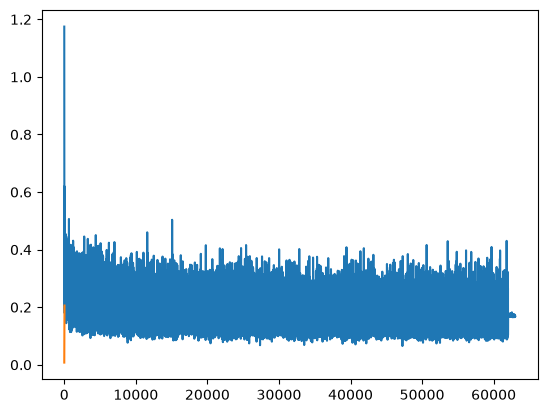

In [78]:
plt.plot(loss_array)
plt.plot(total_test_loss)
plt.show()

In [79]:
torch.save(housing_model.state_dict(),'california_housing_model.pth')